In [26]:
import pandas as pd
import numpy as np

In [27]:
df = pd.read_csv("../Data-Files/powerplant_data.csv")
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [28]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [29]:
X = df.drop(columns="PE")
y = df["PE"]

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
import torch 
import torch.nn as nn

In [32]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1) 
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

In [33]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [34]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)

### Deep Learning

In [35]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            #1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),

            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),

            # Output
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)

In [36]:
import torch.optim as optim

model = ANN()

crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

#### Train ANN

In [37]:
epochs = 100
train_loss = []
valid_loss = []
best_val_loss = float("inf")

for epoch in range(0, epochs):
    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        # xb - features of one batch
        # yb - lables of one batch
        optimizer.zero_grad()
        outputs = model(xb) # Predicted Output 
        loss = crietrion(outputs, yb) # compute loss
        running_loss += loss.item() # tensor => py float
        loss.backward()
        optimizer.step()

    epoch_train_loss = running_loss / len(train_loader)
    train_loss.append(epoch_train_loss)

    #Validation
    model.eval()
    running_valid_loss = 0.0

    with torch.no_grad(): #no Gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_valid_loss += loss.item()

    epoch_test_loss = running_valid_loss / len(test_loader)
    valid_loss.append(epoch_test_loss)

    print(f"Epoch {epoch+1}/{epochs} | Training Loss = {epoch_train_loss} | Test Loss = {epoch_test_loss}")

    if epoch_test_loss < best_val_loss:
        best_val_loss = epoch_test_loss
        torch.save(model.state_dict(), "best_model.pt")

Epoch 1/100 | Training Loss = 205323.17942708332 | Test Loss = 202113.97526041666
Epoch 2/100 | Training Loss = 190806.90559895834 | Test Loss = 172819.09192708333
Epoch 3/100 | Training Loss = 143447.56910807293 | Test Loss = 111150.73020833333
Epoch 4/100 | Training Loss = 81043.73531901042 | Test Loss = 56101.400130208334
Epoch 5/100 | Training Loss = 41174.017732747394 | Test Loss = 30200.799251302084
Epoch 6/100 | Training Loss = 24047.237707519533 | Test Loss = 19377.311181640624
Epoch 7/100 | Training Loss = 16730.13466796875 | Test Loss = 14301.240364583333
Epoch 8/100 | Training Loss = 12585.844966634115 | Test Loss = 10708.479085286459
Epoch 9/100 | Training Loss = 9296.544317626953 | Test Loss = 7740.748624674479
Epoch 10/100 | Training Loss = 6615.991825358073 | Test Loss = 5425.79951171875
Epoch 11/100 | Training Loss = 4606.539965820312 | Test Loss = 3714.509586588542
Epoch 12/100 | Training Loss = 3137.7703709920247 | Test Loss = 2528.991591389974
Epoch 13/100 | Training

Text(0, 0.5, 'Losses')

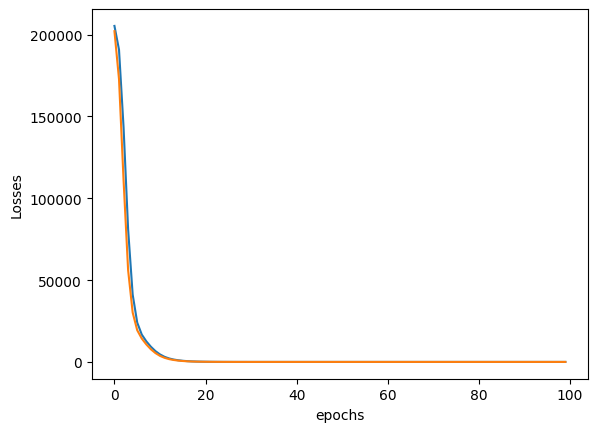

In [38]:
import matplotlib.pyplot as plt

loss = pd.DataFrame({
    "Train_Loss": train_loss,
    "Valid_Loss": valid_loss
})

plt.plot(loss["Train_Loss"], label="Training Loss")
plt.plot(loss["Valid_Loss"], label="Validation Loss")

plt.xlabel("epochs")
plt.ylabel("Losses")

In [ ]:
model.load_state_dict(torch.load("best_model.pt")) # loading the model

<All keys matched successfully>

In [41]:
model.eval()
with torch.no_grad():
    train_pred = model(X_train_tensor)
    test_pred = model(X_test_tensor)

    train_mse_loss = crietrion(train_pred, y_train_tensor)
    test_mse_loss = crietrion(test_pred, y_test_tensor)

print("Train MSE loss: \t", train_mse_loss.item())
print("Test MSE loss: \t", test_mse_loss.item())

Train MSE loss: 	 20.457313537597656
Test MSE loss: 	 18.70227813720703


In [42]:
from sklearn.metrics import r2_score

print("R2 Score Train:\t", r2_score(y_train_tensor, train_pred))
print("R2 Score Test:\t", r2_score(y_test_tensor, test_pred))

R2 Score Train:	 0.9300657510757446
R2 Score Test:	 0.9346403479576111


In [46]:
predicted_df = pd.DataFrame(test_pred.numpy(), columns=["Predicted"])
actual_df = pd.DataFrame(y_test_tensor.numpy(), columns=["Actual"])

df = pd.concat([predicted_df, actual_df], axis=1)
df

,Predicted,Actual
0,435.268066,433.269989
1,436.690186,438.160004
2,461.107361,458.420013
3,476.004150,480.820007
4,435.159851,441.410004
...,...,...
1909,451.234619,456.700012
1910,431.498047,438.040009
1911,467.593384,467.799988
1912,430.886230,437.140015


In [47]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rfr = RandomForestRegressor(max_depth=5)
rfr.fit(X_train_scaled, y_train)
y_pred = rfr.predict(X_test_scaled)

print("MSE:",mean_squared_error(y_test, y_pred))
print("R2 score:\t", r2_score(y_test, y_pred))


MSE: 16.313552812706835
R2 score:	 0.9429883359875958
